In [2]:
# Import libraries
import os
os.chdir("D:\\DESKTOP\\Current-Projects\\tbrucei_docking_data\\ML-steps\\Scaffold-Split-ML\\positive-tbrucie")
os.listdir()

['positive_rdkit_descriptors.csv',
 'positive_tbrucie.txt',
 'scaffold_rdkit.csv',
 'tb-ml-scaffold-CV-Features.ipynb.ipynb']

In [3]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.impute import SimpleImputer

from scipy.stats import pearsonr, spearmanr
from sklearn.model_selection import ( 
    train_test_split, 
    GroupKFold, 
    GroupShuffleSplit,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib

In [4]:
# Load Dataset and prepare it
tb_pos = pd.read_csv("positive_rdkit_descriptors.csv", header=0)
print('shape of tb_neg: ', tb_pos.shape)
pos_deltaG = pd.read_csv("positive_tbrucie.txt", header=0, sep=rf'\s+')
print('shape of neg_deltaG: ', pos_deltaG.shape)
scaffold_rdkit = pd.read_csv('scaffold_rdkit.csv', header=0, sep=',')
print('shape of scaffold_rdkit: ', scaffold_rdkit.shape)

shape of tb_neg:  (7084, 218)
shape of neg_deltaG:  (7085, 2)
shape of scaffold_rdkit:  (12966, 2)


In [5]:
print('#' * 80)
print("Top 10 rows of nb_pos")
print(tb_pos.head(10))
print('#' * 80)
print('Top 10 rows of neg_deltaG')
print(pos_deltaG.head(10))
print('#' * 80)
print('Top 10 rows of scaffold_rdkit')
print(scaffold_rdkit.head(10))

################################################################################
Top 10 rows of nb_pos
                Molecule  MaxAbsEStateIndex  MaxEStateIndex  \
0  ZINC000000000910.mol2          12.564424       12.564424   
1  ZINC000000001690.mol2           2.273608        2.273608   
2  ZINC000000029877.mol2          11.879815       11.879815   
3  ZINC000000033416.mol2          12.596609       12.596609   
4  ZINC000000034999.mol2          12.836321       12.836321   
5  ZINC000000040506.mol2          12.010189       12.010189   
6  ZINC000000041501.mol2          12.462234       12.462234   
7  ZINC000000041615.mol2          12.723689       12.723689   
8  ZINC000000041676.mol2          12.370950       12.370950   
9  ZINC000000045096.mol2          12.970061       12.970061   

   MinAbsEStateIndex  MinEStateIndex       qed        SPS    MolWt  \
0           0.009537       -4.488118  0.912652  11.526316  287.242   
1           1.335566        1.335566  0.550299  13.125000  244.

In [7]:
# Remove '.mol2' suffix from column 'Molecule' in data frame tb_pos &tb_neg
tb_pos['Molecule'] = tb_pos['Molecule'].str.removesuffix('.mol2')
# Merging two data frames based on a column value
df_pos = pd.merge(tb_pos, pos_deltaG, on='Molecule', how='inner')
# Print TOP 10 rows of each data frame
print(df_pos.head())
print('#' * 80)

           Molecule  MaxAbsEStateIndex  MaxEStateIndex  MinAbsEStateIndex  \
0  ZINC000000000910          12.564424       12.564424           0.009537   
1  ZINC000000001690           2.273608        2.273608           1.335566   
2  ZINC000000029877          11.879815       11.879815           0.084418   
3  ZINC000000033416          12.596609       12.596609           0.129331   
4  ZINC000000034999          12.836321       12.836321           0.054074   

   MinEStateIndex       qed        SPS    MolWt  HeavyAtomMolWt  ExactMolWt  \
0       -4.488118  0.912652  11.526316  287.242         281.194  287.010757   
1        1.335566  0.550299  13.125000  244.384         232.288  244.038042   
2       -0.315370  0.793268   8.937500  278.109         270.045  276.985074   
3       -4.556286  0.696213  11.272727  314.223         305.151  314.062675   
4       -0.874413  0.579465  28.476190  306.789         287.637  306.102272   

   ...  fr_sulfonamd  fr_sulfone  fr_term_acetylene  fr_tetraz

In [8]:
print('Before combining, shapes of data frames: ', df_pos.shape)
print('Shape of scaffold_rdkit: ', scaffold_rdkit.shape)
df_tb_scaffold = pd.merge(df_pos, scaffold_rdkit, on='Molecule', how='inner')
print('Shape of df_tb_scaffold: ', df_tb_scaffold.shape)
# Remove 'Molecule' column from the data frame
new_df_tb_scaffold = df_tb_scaffold.drop(columns='Molecule')
print('Shpae of new_df_tb_scaffold: ', new_df_tb_scaffold.shape)

Before combining, shapes of data frames:  (7084, 219)
Shape of scaffold_rdkit:  (12966, 2)
Shape of df_tb_scaffold:  (7084, 220)
Shpae of new_df_tb_scaffold:  (7084, 219)


In [9]:
# Checking missing values from each feature
print('Checking missing values: ', new_df_tb_scaffold.isnull().sum()[new_df_tb_scaffold.isnull().sum() > 0])
print('Checking missing values in scaffold_rdkit: ', scaffold_rdkit.isnull().sum()[scaffold_rdkit.isnull().sum() > 0])
# print the list of missing values rows
new_df_tb_scaffold[new_df_tb_scaffold.isna().any(axis=1)]

Checking missing values:  Scaffold    40
dtype: int64
Checking missing values in scaffold_rdkit:  Scaffold    41
dtype: int64


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea,BindingEnergyDiff,Scaffold
480,9.960733,9.960733,2.109169,-2.500926,0.346644,19.428571,208.122,200.058,208.023014,82,...,0,0,0,0,0,0,0,0,2.0,NaN
502,10.199306,10.199306,1.620556,-3.460648,0.447381,16.714286,205.098,200.058,205.000088,80,...,0,0,0,0,0,0,0,0,2.1,NaN
503,10.199306,10.199306,1.620556,-3.460648,0.447381,16.714286,205.098,200.058,205.000088,80,...,0,0,0,0,0,0,0,0,2.5,NaN
504,10.199306,10.199306,1.620556,-3.460648,0.447381,16.714286,205.098,200.058,205.000088,80,...,0,0,0,0,0,0,0,0,2.2,NaN
521,11.049541,11.049541,0.801435,-2.443773,0.512224,13.800000,219.169,208.081,219.051026,86,...,0,0,0,0,0,0,0,0,1.8,NaN
530,11.133526,11.133526,0.038241,-0.655093,0.296936,9.500000,200.234,184.106,200.104859,80,...,0,0,0,0,0,0,0,0,1.8,NaN
534,11.552917,11.552917,0.070185,-1.775949,0.503025,13.866667,216.233,200.105,216.099774,86,...,0,0,0,0,0,0,0,0,1.8,NaN
542,11.050970,11.050970,1.417502,-3.449583,0.295459,15.166667,260.158,252.094,260.029162,100,...,0,0,0,0,0,0,0,0,2.1,NaN
543,10.646458,10.646458,0.236019,-3.006273,0.467529,16.125000,231.180,220.092,231.052123,92,...,0,0,0,0,0,0,0,0,1.9,NaN
547,10.936855,10.936855,0.080150,-1.686764,0.487010,14.533333,215.269,196.117,215.128883,88,...,0,0,0,0,0,0,3,0,1.9,NaN


In [10]:
# Delete missing values
new_df_tb_scaffold.dropna(inplace=True)
print('Shape of data frame after removing nulll values: ', new_df_tb_scaffold.shape)
# Check to list the missing values after deletion
new_df_tb_scaffold[new_df_tb_scaffold.isna().any(axis=1)]

Shape of data frame after removing nulll values:  (7044, 219)


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea,BindingEnergyDiff,Scaffold


In [11]:
# Checking column data types of df_tb
for col in new_df_tb_scaffold.columns:
    print(col, new_df_tb_scaffold[col].dtype)

MaxAbsEStateIndex float64
MaxEStateIndex float64
MinAbsEStateIndex float64
MinEStateIndex float64
qed float64
SPS float64
MolWt float64
HeavyAtomMolWt float64
ExactMolWt float64
NumValenceElectrons int64
NumRadicalElectrons int64
MaxPartialCharge float64
MinPartialCharge float64
MaxAbsPartialCharge float64
MinAbsPartialCharge float64
FpDensityMorgan1 float64
FpDensityMorgan2 float64
FpDensityMorgan3 float64
BCUT2D_MWHI float64
BCUT2D_MWLOW float64
BCUT2D_CHGHI float64
BCUT2D_CHGLO float64
BCUT2D_LOGPHI float64
BCUT2D_LOGPLOW float64
BCUT2D_MRHI float64
BCUT2D_MRLOW float64
AvgIpc float64
BalabanJ float64
BertzCT float64
Chi0 float64
Chi0n float64
Chi0v float64
Chi1 float64
Chi1n float64
Chi1v float64
Chi2n float64
Chi2v float64
Chi3n float64
Chi3v float64
Chi4n float64
Chi4v float64
HallKierAlpha float64
Ipc float64
Kappa1 float64
Kappa2 float64
Kappa3 float64
LabuteASA float64
PEOE_VSA1 float64
PEOE_VSA10 float64
PEOE_VSA11 float64
PEOE_VSA12 float64
PEOE_VSA13 float64
PEOE_VSA14 floa

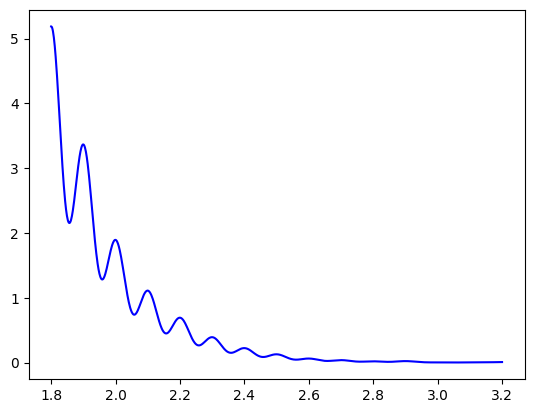

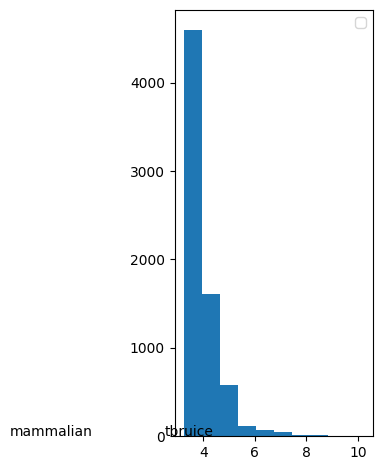

In [12]:
# distribution of 'BindingEnergyDiff' values
from scipy.stats import gaussian_kde

plt.figure()
def plot_values(data_frame):
    values = data_frame['BindingEnergyDiff'].dropna().values
    kde = gaussian_kde(values)
    x_vals = np.linspace(values.min(), values.max(), 1000)
    y_vals = kde(x_vals)
    return x_vals, y_vals

dx1, dy1 = plot_values(new_df_tb_scaffold)
BE = new_df_tb_scaffold["BindingEnergyDiff"]
plt.plot(dx1, dy1, color = 'blue', label='Binding Energy Difference')
plt.show()
plt.hist(BE**2)

plt.legend()
plt.text(-3.5, 0.4, 'mammalian')
plt.text(2.5, 0.4, 'tbruice')
plt.tight_layout()
plt.show()

In [13]:
# EXPLORATORY DATA ANALYSIS (EDA) 
# Finding relationship between features and remove constant value features, and \
# features containing correlation +1 or -1 values
columns_list = new_df_tb_scaffold.columns
uniq_value_columns = []
for col in columns_list:
    if new_df_tb_scaffold[col].nunique() == 1 :
        uniq_value_columns.append(col)

print('Uniq value columns: ', uniq_value_columns)
print('Total columns have unique value: ', len(uniq_value_columns))

# Remove uniq_value_columns from the data frame
print('Shape of data frame before deleting unique values: ', new_df_tb_scaffold.shape)
uniq_del_df_tb_scaffold = new_df_tb_scaffold.drop(columns=uniq_value_columns)
print('Shape of data frame after deleting unique values: ', uniq_del_df_tb_scaffold.shape)

# Calcualting data frame features correlation values for numeric features
# Calculate dimensions based on the number of features
num_features = len(uniq_del_df_tb_scaffold.select_dtypes(include=['number']).columns)
# Dynamically size the figure (e.g., 0.9 inches per feature)
plt.figure(figsize=(num_features * 0.9, num_features * 0.9))
sns.heatmap(uniq_del_df_tb_scaffold.corr(numeric_only=True), fmt=".2f", annot=True, cmap='coolwarm', vmin=-1, vmax=1)
# Remove limits on rows, columns, and width
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

uniq_del_df_tb_scaffold.corr(numeric_only=True).style.format("{: .2f}")


Uniq value columns:  ['NumRadicalElectrons', 'SMR_VSA8', 'SlogP_VSA9', 'NumAtomStereoCenters', 'NumUnspecifiedAtomStereoCenters', 'fr_isocyan', 'fr_isothiocyan', 'fr_thiocyan']
Total columns have unique value:  8
Shape of data frame before deleting unique values:  (7044, 219)
Shape of data frame after deleting unique values:  (7044, 211)


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,MaxPartialCharge,MinPartialCharge,MaxAbsPartialCharge,MinAbsPartialCharge,FpDensityMorgan1,FpDensityMorgan2,FpDensityMorgan3,BCUT2D_MWHI,BCUT2D_MWLOW,BCUT2D_CHGHI,BCUT2D_CHGLO,BCUT2D_LOGPHI,BCUT2D_LOGPLOW,BCUT2D_MRHI,BCUT2D_MRLOW,AvgIpc,BalabanJ,BertzCT,Chi0,Chi0n,Chi0v,Chi1,Chi1n,Chi1v,Chi2n,Chi2v,Chi3n,Chi3v,Chi4n,Chi4v,HallKierAlpha,Ipc,Kappa1,Kappa2,Kappa3,LabuteASA,PEOE_VSA1,PEOE_VSA10,PEOE_VSA11,PEOE_VSA12,PEOE_VSA13,PEOE_VSA14,PEOE_VSA2,PEOE_VSA3,PEOE_VSA4,PEOE_VSA5,PEOE_VSA6,PEOE_VSA7,PEOE_VSA8,PEOE_VSA9,SMR_VSA1,SMR_VSA10,SMR_VSA2,SMR_VSA3,SMR_VSA4,SMR_VSA5,SMR_VSA6,SMR_VSA7,SMR_VSA9,SlogP_VSA1,SlogP_VSA10,SlogP_VSA11,SlogP_VSA12,SlogP_VSA2,SlogP_VSA3,SlogP_VSA4,SlogP_VSA5,SlogP_VSA6,SlogP_VSA7,SlogP_VSA8,TPSA,EState_VSA1,EState_VSA10,EState_VSA11,EState_VSA2,EState_VSA3,EState_VSA4,EState_VSA5,EState_VSA6,EState_VSA7,EState_VSA8,EState_VSA9,VSA_EState1,VSA_EState10,VSA_EState2,VSA_EState3,VSA_EState4,VSA_EState5,VSA_EState6,VSA_EState7,VSA_EState8,VSA_EState9,FractionCSP3,HeavyAtomCount,NHOHCount,NOCount,NumAliphaticCarbocycles,NumAliphaticHeterocycles,NumAliphaticRings,NumAmideBonds,NumAromaticCarbocycles,NumAromaticHeterocycles,NumAromaticRings,NumBridgeheadAtoms,NumHAcceptors,NumHDonors,NumHeteroatoms,NumHeterocycles,NumRotatableBonds,NumSaturatedCarbocycles,NumSaturatedHeterocycles,NumSaturatedRings,NumSpiroAtoms,Phi,RingCount,MolLogP,MolMR,fr_Al_COO,fr_Al_OH,fr_Al_OH_noTert,fr_ArN,fr_Ar_COO,fr_Ar_N,fr_Ar_NH,fr_Ar_OH,fr_COO,fr_COO2,fr_C_O,fr_C_O_noCOO,fr_C_S,fr_HOCCN,fr_Imine,fr_NH0,fr_NH1,fr_NH2,fr_N_O,fr_Ndealkylation1,fr_Ndealkylation2,fr_Nhpyrrole,fr_SH,fr_aldehyde,fr_alkyl_carbamate,fr_alkyl_halide,fr_allylic_oxid,fr_amide,fr_amidine,fr_aniline,fr_aryl_methyl,fr_azide,fr_azo,fr_barbitur,fr_benzene,fr_benzodiazepine,fr_bicyclic,fr_diazo,fr_dihydropyridine,fr_epoxide,fr_ester,fr_ether,fr_furan,fr_guanido,fr_halogen,fr_hdrzine,fr_hdrzone,fr_imidazole,fr_imide,fr_ketone,fr_ketone_Topliss,fr_lactam,fr_lactone,fr_methoxy,fr_morpholine,fr_nitrile,fr_nitro,fr_nitro_arom,fr_nitro_arom_nonortho,fr_nitroso,fr_oxazole,fr_oxime,fr_para_hydroxylation,fr_phenol,fr_phenol_noOrthoHbond,fr_phos_acid,fr_phos_ester,fr_piperdine,fr_piperzine,fr_priamide,fr_prisulfonamd,fr_pyridine,fr_quatN,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiophene,fr_unbrch_alkane,fr_urea,BindingEnergyDiff
MaxAbsEStateIndex,1.00,1.00,-0.29,-0.18,-0.11,0.01,0.51,0.51,0.51,0.50,0.33,-0.01,0.02,0.34,-0.17,-0.14,-0.08,-0.01,-0.16,0.26,-0.22,0.13,-0.25,0.06,-0.18,0.31,-0.30,0.44,0.52,0.47,0.47,0.49,0.44,0.44,0.38,0.39,0.30,0.32,0.24,0.26,-0.34,0.15,0.50,0.41,0.30,0.49,0.05,0.08,0.06,0.17,0.22,0.08,0.37,0.15,-0.03,-0.05,0.19,0.21,0.19,0.18,0.32,0.25,-0.01,-0.05,-0.01,0.09,0.17,0.33,-0.11,0.19,0.20,0.06,0.00,0.24,0.29,0.04,0.17,0.28,0.00,-0.09,0.11,0.21,0.36,0.10,0.38,0.25,0.15,-0.03,0.20,0.22,-0.25,-0.01,0.18,-0.01,0.44,-0.17,-0.08,-0.20,0.25,-0.07,0.02,0.01,-0.02,0.50,-0.06,0.19,-0.03,0.30,0.15,0.35,0.31,-0.12,0.17,-0.02,0.11,-0.02,0.26,0.15,0.19,-0.05,0.22,0.08,0.05,0.37,0.30,0.24,0.45,-0.02,-0.04,-0.06,-0.19,-0.09,-0.20,-0.09,0.03,-0.08,-0.08,0.38,0.38,0.00,-0.00,-0.01,-0.04,0.06,-0.14,0.05,0.01,0.12,-0.09,0.01,-0.03,-0.01,0.09,0.03,0.35,0.00,0.13,0.07,-0.08,-0.06,0.06,0.31,0.01,0.07,-0.01,0.02,-0.02,0.06,0.07,-0.03,-0.05,0.15,0.04,-0.05,-0.04,0.19,0.13,0.13,0.01,-0.00,0.05,0.02,-0.01,-0.07,-0.04,-0.03,-0.03,-0.02,-0.07,0.11,0.05,0.05,0.00,0.00,0.10,0.05,-0.01,0.01,0.01,-0.05,0.03,0.06,-0.01,-0.02,-0.05,0.11,0.04,-0.01,0.08,0.06
MaxEStateIndex,1.00,1.00,-0.29,-0.18,-0.11,0.01,0.51,0.51,0.51,0.50,0.33,-0.01,0.02,0.34,-0.17,-0.14,-0.08,-0.01,-0.16,0.26,-0.22,0.13,-0.25,0.06,-0.18,0.31,-0.30,0.44,0.52,0.47,0.47,0.49,0.44,0.44,0.38,0.39,0.30,0.32,0.24,0.26,-0.34,0.15,0.50,0.41,0.30,0.49,0.05,0.08,0.06,0.17,0.22,0.08,0.37,0.15,-0.03,-0.05,0.19,0.21,0.19,0.18,0.32,0.25,-0.01,-0.05,-0.01,0.09,0.17,0

In [14]:
# Selecting Features which have correlation values > 0.95 or < -0.95
corr = uniq_del_df_tb_scaffold.corr(numeric_only=True)
pairs = []
threshold = 0.95

for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        value = corr.iloc[i, j]

        if abs(value) >= threshold:
            pairs.append([
                corr.index[i],
                corr.columns[j],
                value
            ])

high_corr_pairs = pd.DataFrame(pairs, columns=['Feature_1', 'Feature_2', 'Correlation'])

print('Shape of highly correlated features: ', high_corr_pairs['Feature_1'].unique())
print('#' * 80)
print('Shape of highly correlated features: ', high_corr_pairs['Feature_2'].unique())
print('#' * 80)
print(high_corr_pairs)

Shape of highly correlated features:  <StringArray>
[     'MaxAbsEStateIndex',                  'MolWt',         'HeavyAtomMolWt',
             'ExactMolWt',    'NumValenceElectrons',       'MaxPartialCharge',
       'MinPartialCharge',                   'Chi0',                  'Chi0n',
                  'Chi0v',                   'Chi1',                  'Chi1n',
                  'Chi2n',                  'Chi2v',                  'Chi3n',
                  'Chi3v',                 'Kappa1',                 'Kappa2',
                 'Kappa3',              'LabuteASA',               'SMR_VSA7',
         'HeavyAtomCount',              'NHOHCount',          'NumAmideBonds',
 'NumAromaticCarbocycles',               'fr_Ar_NH',                 'fr_COO',
                 'fr_C_O',              'fr_phenol',           'fr_phos_acid']
Length: 30, dtype: str
################################################################################
Shape of highly correlated features:  <StringArray>
[ 

In [15]:
corr_columns = high_corr_pairs['Feature_1'].unique()
print('Shape before deleting corr_columns: ', uniq_del_df_tb_scaffold.shape)
corr_uniq_del_df_tb_scaffold = uniq_del_df_tb_scaffold.drop(columns=corr_columns)
print('Shape after deleting corr_columns: ', corr_uniq_del_df_tb_scaffold.shape)

Shape before deleting corr_columns:  (7044, 211)
Shape after deleting corr_columns:  (7044, 181)


In [16]:
corr_A = corr_uniq_del_df_tb_scaffold.corr(numeric_only=True)
pairs = []
threshold = 0.95

for i in range(len(corr_A.columns)):
    for j in range(i+1, len(corr_A.columns)):
        value = corr_A.iloc[i, j]

        if abs(value) >= threshold:
            pairs.append([
                corr_A.index[i],
                corr_A.columns[j],
                value
            ])

high_corr_pairs_A = pd.DataFrame(pairs, columns=['Feature_1', 'Feature_2', 'Correlation'])
high_corr_pairs_A

,Feature_1,Feature_2,Correlation


In [17]:
# Remove duplicates
print('Shape of before removing duplicates : ', corr_uniq_del_df_tb_scaffold.shape)
clean_df = corr_uniq_del_df_tb_scaffold.drop_duplicates(ignore_index=True)
print('Shape of clean_df dataframe: ', clean_df.shape)

Shape of before removing duplicates :  (7044, 181)
Shape of clean_df dataframe:  (6881, 181)


In [18]:
#======================================================================
# UNIQUE SCAFFOLD
#======================================================================
print("\n Number of unique scaffolds: ", clean_df["Scaffold"].nunique())

print("\n Top Scaffolds: ", clean_df["Scaffold"].value_counts().head(20))


 Number of unique scaffolds:  3675

 Top Scaffolds:  Scaffold
c1ccccc1                                                   261
O=c1/c(=C/c2ccccc2)sc2n1C(c1ccccc1)C1=C(N=2)c2ccccc2CC1     81
C1CCC2C(C1)CCC1C3CCCC3CCC21                                 73
C1=C2CCCCC2C2CCC3CCCC3C2C1                                  65
O=C1C2ON(c3ccccc3)C(c3ccccc3)C2C(=O)N1c1ccccc1              51
O=C(COC(=O)c1cccc(N2C(=O)c3ccccc3C2=O)c1)Nc1ccccc1          42
O=C(COC(=O)c1cccc(N2C(=O)C3CC=CCC3C2=O)c1)Nc1ccccc1         42
O=C1CCC2C1CCC1C3CCCCC3CCC21                                 38
O=C1[N-]C(=O)N(c2ccccc2)C(=O)/C1=C/c1ccc(OCc2ccccc2)cc1     38
O=c1/c(=C\c2ccccc2)sc2n1C(c1ccccc1)C1=C(N=2)c2ccccc2CC1     36
c1ccc(-c2ccco2)cc1                                          34
c1ccc(-n2ccnn2)cc1                                          33
O=C(COC(=O)c1ccc2c(c1)C(=O)N(c1ccccc1)C2=O)c1ccccc1         33
O=C(NCc1ccccc1)c1cccc(-c2nc3cccnc3[nH]2)c1                  24
O=C1C=C2CCC3C4CCCC4CCC3C2CC1                           

In [20]:
#=======================================================================
# SEPARATE FEATURE, TARGET, AND SCAFFOLD GROUP
#=======================================================================
y = clean_df["BindingEnergyDiff"].copy()

groups = clean_df["Scaffold"].copy()

X = clean_df.drop(columns=["BindingEnergyDiff", "Scaffold"]).copy()

print("X shape: ", X.shape)
print("y shape: ", y.shape)
print("groups shape: ", groups.shape)

X shape:  (6881, 179)
y shape:  (6881,)
groups shape:  (6881,)


In [21]:
#===============================================================
# SCAFFOLD-BASED 80/20 TRAIN-TEST SPLIT
#===============================================================
outer_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)

train_idx, test_idx = next(outer_split.split(X, y, groups=groups))

#-----------------------------------------------------------------
# Now create the datasets
#-----------------------------------------------------------------
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

In [22]:
#==================================================================
# Verify the Scaffold separaton /OR/ VERIFY NO SCAFFOLD LEAKAGE
# ================================================================= 
train_scaffolds = set(groups_train.unique())

test_scaffolds = set(groups_test.unique())

overlap = train_scaffolds.intersection(test_scaffolds)

print("Training molecules: ", len(X_train))
print("Test molecules: ", len(X_test))

print("Training scaffolds: ", len(train_scaffolds))
print("Test scaffolds: ", len(test_scaffolds))

print("Overlapping scaffolds: ", len(overlap))

assert len(overlap) == 0, ("ERROR: Scaffold leakage detected!")

Training molecules:  5583
Test molecules:  1298
Training scaffolds:  2940
Test scaffolds:  735
Overlapping scaffolds:  0


In [23]:
print(f"Training percentage: {len(X_train)/len(X)*100:.2f}%")

print(f"Test percentage: {len(X_test)/len(X)*100:.2f}%")

Training percentage: 81.14%
Test percentage: 18.86%


In [24]:
#================================================================
# NESTED GROUP CV
#================================================================
OUTER_FOLDS = 5
INNER_FOLDS = 5

outer_cv = GroupKFold(n_splits = OUTER_FOLDS)
inner_cv = GroupKFold(n_splits = INNER_FOLDS)

In [26]:
#===============================================================
# EVALUATION FUNCTION
#===============================================================

def calculate_metrics(y_true, y_pred):

    r2 = r2_score(y_true, y_pred)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    mae = mean_absolute_error(y_true, y_pred)

    pearson_r, pearson_p = pearsonr(y_true, y_pred)

    spearman_rho, spearman_p = spearmanr(y_true, y_pred)

    return {
        "R2" : r2,
        "RMSE" : rmse,
        "MAE" : mae,
        "Pearson_r" : pearson_r,
        "Pearson_p" : pearson_p,
        "Spearman_rho" : spearman_rho,
        "Spearman_p" : spearman_p
    }


In [27]:
#==============================================================
# MODEL 1: XGBoost
#==============================================================
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", XGBRegressor(objective="reg:squarederror", random_state=42, tree_method="hist"))
])

xgb_params = {
    "model__n_estimators" : [200, 400, 600, 800, 1000],
    "model__max_depth" : [2, 3, 4, 5, 6, 8],
    "model__learning_rate" : [0.01, 0.03, 0.05, 0.10, 0.15],
    "model__subsample" : [0.6, 0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree" : [0.6, 0.7, 0.8, 0.9, 1.0],
    "model__min_child_weight" : [1, 3, 5, 10],
    "model__reg_alpha" : [0, 0.01, 0.1, 1],
    "model__reg_lambda" : [0.1, 1, 5, 10]
}

In [28]:
#==========================================================
# MODEL 2: RANDOM FOREST
#==========================================================
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", RandomForestRegressor(random_state=42))
])
rf_params = {
    "model__n_estimators" : [300, 500, 800, 1000],
    "model__max_depth" : [None, 10, 20, 30, 40],
    "model__min_samples_split" : [2, 5, 10, 20],
    "model__min_samples_leaf" : [1, 2, 4, 8],
    "model__max_features" : [0.5, 0.7, 1.0, "sqrt"],
    "model__bootstrap" : [True, False]
}

In [29]:
#==================================================================
# MODEL 3: SVR-RBF
#==================================================================
svr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("scaler", StandardScaler()),
    ("model", SVR(kernel = "rbf"))
])

svr_params = {
    "model__C" : [0.1, 1, 10, 50, 100, 500, 1000],
    "model__gamma" : ["scale", "auto", 0.0001, 0.001, 0.01, 0.1],
    "model__epsilon" : [0.001, 0.01, 0.05, 0.1, 0.2, 0.5]
}

In [30]:
#=============================================================
# MODEL 4: CATBOOST
#=============================================================
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", CatBoostRegressor(loss_function="RMSE", random_seed=42, verbose=False, thread_count=-1))
])

cat_params = {
    "model__iterations" : [300, 500, 800, 1000],
    "model__depth" : [4, 5, 6, 7, 8, 10],
    "model__learning_rate" : [0.01, 0.03, 0.05, 0.10, 0.15],
    "model__l2_leaf_reg" : [1, 3, 5, 10, 20],
    "model__subsample" : [0.7, 0.8, 0.9, 1.0]
}

In [31]:
#======================================================================
# MODEL 5: LIGHTGBM
#=======================================================================
lgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", LGBMRegressor(objective="regression", random_state=42, verbosity=1))
])

lgb_params = {
    "model__n_estimators" : [100, 200, 400, 600, 800],
    "model__learning_rate" : [0.01, 0.03, 0.05, 0.10],
    "model__num_leaves" : [7, 15, 31, 50, 75],
    "model__max_depth" : [-1, 3, 5, 7, 10],
    "model__min_child_samples" : [5, 10, 20, 30, 50],
    "model__subsample" : [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree" : [0.6, 0.8, 1.0],
    "model__reg_alpha" : [0, 0.01, 0.1, 1],
    "model__reg_lambda" : [0, 0.1, 1, 5, 10]
}

In [32]:
#==============================================================
# Put MODELS into one dictionary
#==============================================================
models = {
    "XGBoost" : {
        "pipeline" : xgb_pipeline,
        "params" : xgb_params,
        "n_iter" : 40
    },

    "SVR-RBF" : {
        "pipeline" : svr_pipeline,
        "params" : svr_params,
        "n_iter" : 40
    },

    "CatBoost" : {
        "pipeline" : cat_pipeline,
        "params" : cat_params,
        "n_iter" : 40
    },

    "LightGBM" : {
        "pipeline" : lgb_pipeline,
        "params" : lgb_params,
        "n_iter" : 40
    },

        "Random Forest" : {
        "pipeline" : rf_pipeline,
        "params" : rf_params,
        "n_iter" : 40
    }

}

In [33]:
#================================================================
# NESTED CV FUNCTION (This is the heart of the analysis)
#================================================================
def nested_group_cv(model_name, pipeline, param_grid, X_data, y_data, groups_data, outer_cv, inner_cv,
        n_iter=40):
    print("\n")
    print("=" * 80)
    print(f"NESTED CV: {model_name}")
    print("=" * 80)

    outer_results = []

    fold_number = 1

    for outer_train_idx, outer_valid_idx in outer_cv.split(X_data, y_data, groups=groups_data):
        print("\n")
        print("-" * 80)
        print(f"OUTER FOLD {fold_number}")
        print("-" * 80)

        X_outer_train = X_data.iloc[outer_train_idx]

        X_outer_valid = X_data.iloc[outer_valid_idx]

        y_outer_train = y_data.iloc[outer_train_idx]

        y_outer_valid = y_data.iloc[outer_valid_idx]

        groups_outer_train = groups_data.iloc[outer_train_idx]

        groups_outer_valid = groups_data.iloc[outer_valid_idx]

        #---------------------------------------------------------
        # Verify no scaffold overlap
        #---------------------------------------------------------
        overlap = set(groups_outer_train.unique()).intersection(set(groups_outer_valid.unique()))
        assert len(overlap) == 0, (f"Scaffold leakage in outer fold {fold_number}")

        print("Outer training molecules: ", len(X_outer_train))
        print("Outer validation molecules: ", len(X_outer_valid))
        print("Outer training scaffolds: ", groups_outer_train.nunique())
        print("Outer validation scaffolds: ", groups_outer_valid.nunique())

        #------------------------------------------------------------------
        # INNER CV HYPERPARAMETER SEARCH
        #------------------------------------------------------------------
        search = RandomizedSearchCV(
            estimator = pipeline,
            param_distributions = param_grid,
            n_iter = n_iter,
            scoring = "neg_root_mean_squared_error",
            cv = inner_cv,
            random_state = 42 + fold_number,
            refit = True,
            verbose = 1,
            return_train_score = False
        )

        #--------------------------------------------------------------
        # Hyperparameter optimization
        # ONLY outer training data
        #--------------------------------------------------------------
        search.fit(X_outer_train, y_outer_train, groups=groups_outer_train)

        print("\n Best inner-CV RMSE: ", search.best_score_)
        print("\n Best parameters: ", search.best_params_)

        #-----------------------------------------------------------------
        # Predict outer validation set
        #-----------------------------------------------------------------
        outer_predictions = search.predict(X_outer_valid)
        metrics = calculate_metrics(y_outer_valid, outer_predictions)

        print("\n Outer validation metrics:")

        for metric, value in metrics.items():
            if "p" not in metric:
                print(f"{metric}:{value:.5f}")

        metrics["Fold"] = fold_number
        outer_results.append(metrics)
        fold_number += 1

    #-------------------------------------------------------------------
    # Convert results to dataframe
    #-------------------------------------------------------------------
    outer_results_df = pd.DataFrame(outer_results)
    return outer_results_df
  

In [34]:
#===========================================================
# RUN NESTED CV FOR ALL MODELS
#===========================================================
nested_results = {}

for model_name, model_info in models.items():
    results = nested_group_cv(
        model_name = model_name,
        pipeline = model_info["pipeline"],
        param_grid = model_info["params"],
        X_data = X_train,
        y_data = y_train,
        groups_data = groups_train,
        outer_cv = outer_cv,
        inner_cv = inner_cv,
        n_iter = model_info["n_iter"]
    )

    nested_results[model_name] = results



NESTED CV: XGBoost


--------------------------------------------------------------------------------
OUTER FOLD 1
--------------------------------------------------------------------------------
Outer training molecules:  4466
Outer validation molecules:  1117
Outer training scaffolds:  2362
Outer validation scaffolds:  578
Fitting 5 folds for each of 40 candidates, totalling 200 fits

 Best inner-CV RMSE:  -0.17167737182823817

 Best parameters:  {'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__reg_alpha': 0, 'model__n_estimators': 600, 'model__min_child_weight': 1, 'model__max_depth': 5, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.6}

 Outer validation metrics:
R2:0.00786
RMSE:0.17453
MAE:0.12451
Pearson_r:0.13414


--------------------------------------------------------------------------------
OUTER FOLD 2
--------------------------------------------------------------------------------
Outer training molecules:  4466
Outer validation molecules:  1117
Out

In [35]:
#=========================================================
# NESTED CV RESULTS
#=========================================================

for model_name, result_df, in nested_results.items():
    print("\n")
    print("=" * 80)
    print(model_name)
    print("=" * 80)
    print(result_df[["Fold", "R2", "RMSE", "MAE", "Pearson_r", "Spearman_rho"]].round(4))



XGBoost
   Fold      R2    RMSE     MAE  Pearson_r  Spearman_rho
0     1  0.0079  0.1745  0.1245     0.1341        0.1271
1     2  0.0233  0.1719  0.1269     0.1653        0.1624
2     3  0.0610  0.1560  0.1187     0.2497        0.2016
3     4  0.0113  0.1747  0.1259     0.1714        0.1602
4     5  0.0787  0.1864  0.1339     0.2888        0.2755


SVR-RBF
   Fold      R2    RMSE     MAE  Pearson_r  Spearman_rho
0     1  0.0395  0.1717  0.1210     0.2338        0.2243
1     2  0.0037  0.1736  0.1307     0.0635        0.0719
2     3 -0.0278  0.1632  0.1282     0.0411        0.0901
3     4  0.0145  0.1744  0.1221     0.1553        0.1199
4     5  0.0229  0.1920  0.1296     0.2780        0.2433


CatBoost
   Fold      R2    RMSE     MAE  Pearson_r  Spearman_rho
0     1  0.0193  0.1735  0.1239     0.1567        0.1443
1     2  0.0225  0.1720  0.1248     0.1780        0.1539
2     3  0.0612  0.1560  0.1194     0.2485        0.2053
3     4  0.0223  0.1737  0.1251     0.1784        0.1717


In [36]:
#===========================================================================
# STEP 23: NESTED CV SUMMARY and Calculate MEAN & SD
#===========================================================================
nested_summary = []

for model_name, result_df in nested_results.items():
    nested_summary.append({
        "Model" : model_name,
        "CV_R2_mean" : result_df["R2"].mean(),
        "CV_R2_SD" : result_df["R2"].std(),
        "CV_RMSE_mean" : result_df["RMSE"].mean(),
        "CV_RMSE_SD" : result_df["RMSE"].std(),
        "CV_MAE_mean" : result_df["MAE"].mean(),
        "CV_MAE_SD" : result_df["MAE"].std(),
        "CV_Pearson_mean" : result_df["Pearson_r"].mean(),
        "CV_Pearson_SD" : result_df["Pearson_r"].std(),
        "CV_Spearman_mean" : result_df["Spearman_rho"].mean(),
        "CV_Spearman_SD" : result_df["Spearman_rho"].std()
    })

nested_summary_df = pd.DataFrame(nested_summary)
nested_summary_df = nested_summary_df.sort_values("CV_RMSE_mean")

print(nested_summary_df.round(4))

           Model  CV_R2_mean  CV_R2_SD  CV_RMSE_mean  CV_RMSE_SD  CV_MAE_mean  \
4  Random Forest      0.0493    0.0364        0.1716      0.0109       0.1250   
2       CatBoost      0.0444    0.0340        0.1720      0.0103       0.1250   
0        XGBoost      0.0364    0.0317        0.1727      0.0109       0.1260   
3       LightGBM      0.0305    0.0346        0.1732      0.0110       0.1263   
1        SVR-RBF      0.0106    0.0251        0.1750      0.0105       0.1263   

   CV_MAE_SD  CV_Pearson_mean  CV_Pearson_SD  CV_Spearman_mean  CV_Spearman_SD  
4     0.0051           0.2242         0.0759            0.1910          0.0704  
2     0.0045           0.2172         0.0693            0.1952          0.0635  
0     0.0055           0.2019         0.0646            0.1854          0.0569  
3     0.0048           0.2033         0.0824            0.1896          0.0730  
1     0.0045           0.1543         0.1033            0.1499          0.0788  


In [37]:
#==============================================================
# SAVE NESTED CV RESULTS
#==============================================================

nested_summary_df.to_csv("nested_scaffold_CV_summary.csv", index=False)
for model_name, result_df in nested_results.items():
    filename = (model_name.replace(" ", "_").replace("-", "_") + "_nested_CV_folds.csv")

    result_df.to_csv(filename, index=False)

In [38]:
#====================================================================
# FINAL HYPERPARAMETER SEARCH
#====================================================================

final_models = {}
final_search_results = {}

for model_name, model_info in models.items():
    print("\n")
    print("=" * 80)
    print(f"FINAL HYPERPARAMETER SEARCH: {model_name}")
    print("=" * 80)

    search = RandomizedSearchCV(
        estimator = model_info["pipeline"],
        param_distributions = model_info["params"],
        n_iter = model_info["n_iter"],
        scoring = "neg_root_mean_squared_error",
        cv = inner_cv,
        random_state = 42,
        refit = True, 
        verbose = 2,
        return_train_score = True
    )

    search.fit(X_train, y_train, groups = groups_train)

    final_models[model_name] = (search.best_estimator_)

    final_search_results[model_name] = search

    print("\n Best CV RMSE:", search.best_score_)

    print("\n Best parameters: ")

    print(search.best_params_)



FINAL HYPERPARAMETER SEARCH: XGBoost
Fitting 5 folds for each of 40 candidates, totalling 200 fits
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.05, model__max_depth=6, model__min_child_weight=1, model__n_estimators=1000, model__reg_alpha=0.01, model__reg_lambda=10, model__subsample=0.9; total time=   2.9s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.05, model__max_depth=6, model__min_child_weight=1, model__n_estimators=1000, model__reg_alpha=0.01, model__reg_lambda=10, model__subsample=0.9; total time=   2.8s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.05, model__max_depth=6, model__min_child_weight=1, model__n_estimators=1000, model__reg_alpha=0.01, model__reg_lambda=10, model__subsample=0.9; total time=   3.1s
[CV] END model__colsample_bytree=0.8, model__learning_rate=0.05, model__max_depth=6, model__min_child_weight=1, model__n_estimators=1000, model__reg_alpha=0.01, model__reg_lambda=10, model__subsample=0.9; total time=   2.7s
[CV

In [39]:
#================================================================
# FINAL TEST SET EVALUATION
#================================================================
final_test_results = []
test_predictions = {}

for model_name, model in final_models.items():
    print("\n")
    print("=" * 80)
    print(f"FINAL UNTOUCHED TEST: {model_name}")
    print("=" * 80)

    predictions = model.predict(X_test)
    metrics = calculate_metrics(y_test, predictions)
    test_predictions[model_name] = predictions
    row = {"Model" : model_name, **metrics}
    final_test_results.append(row)
    print(f"R2   : {metrics['R2']:.5f}")
    print(f"RMSE   : {metrics['RMSE']:.5f}")
    print(f"MAE   : {metrics['MAE']:.5f}")
    print(f"Pearson r   : {metrics['Pearson_r']:.5f}")
    print(f"Spearman rho: {metrics['Spearman_rho']:.5f}")



FINAL UNTOUCHED TEST: XGBoost
R2   : 0.12649
RMSE   : 0.17946
MAE   : 0.13242
Pearson r   : 0.36955
Spearman rho: 0.30716


FINAL UNTOUCHED TEST: SVR-RBF
R2   : 0.04839
RMSE   : 0.18731
MAE   : 0.13356
Pearson r   : 0.28542
Spearman rho: 0.24905


FINAL UNTOUCHED TEST: CatBoost
R2   : 0.12798
RMSE   : 0.17931
MAE   : 0.13242
Pearson r   : 0.36431
Spearman rho: 0.31031


FINAL UNTOUCHED TEST: LightGBM
R2   : 0.10084
RMSE   : 0.18208
MAE   : 0.13419
Pearson r   : 0.32957
Spearman rho: 0.27769


FINAL UNTOUCHED TEST: Random Forest
R2   : 0.12686
RMSE   : 0.17942
MAE   : 0.13211
Pearson r   : 0.36330
Spearman rho: 0.31185


In [40]:
#=========================================================
# FINAL TEST COMPARISON
#=========================================================

final_test_df = pd.DataFrame(final_test_results)
final_test_df = final_test_df.sort_values("RMSE").reset_index(drop=True)

print("\n")
print("=" * 80)
print("FINAL TEST SET RESULTS")
print("=" * 80)

print(final_test_df[["Model", "R2", "RMSE", "MAE", "Pearson_r", "Spearman_rho"]].round(4))



FINAL TEST SET RESULTS
           Model      R2    RMSE     MAE  Pearson_r  Spearman_rho
0       CatBoost  0.1280  0.1793  0.1324     0.3643        0.3103
1  Random Forest  0.1269  0.1794  0.1321     0.3633        0.3119
2        XGBoost  0.1265  0.1795  0.1324     0.3696        0.3072
3       LightGBM  0.1008  0.1821  0.1342     0.3296        0.2777
4        SVR-RBF  0.0484  0.1873  0.1336     0.2854        0.2491


In [41]:
#===============================================================
# SAVE FINAL RESULTS
#===============================================================
final_test_df.to_csv("final_scaffold_test_results.csv", index=False)

In [42]:
#================================================================
# BEST MODEL
#================================================================
best_model_name = final_test_df.iloc[0]["Model"]
best_model = final_models[best_model_name]
print("Best model: ", best_model_name)
print("\n Best test RMSE: ", final_test_df.iloc[0]["RMSE"])
print("Best test MAE: ", final_test_df.iloc[0]["MAE"])
print("Best test R2: ", final_test_df.iloc[0]["R2"])

Best model:  CatBoost

 Best test RMSE:  0.17930712133989327
Best test MAE:  0.13241762577004093
Best test R2:  0.127982963851499


In [43]:
#====================================================================
# SAVE BEST MODEL
#====================================================================
model_filename = ("best_scaffold_model_" + best_model_name.replace(" ", "_").replace("-", "_") + ".pkl")
joblib.dump(best_model, model_filename)
print("Saved: ", model_filename)

Saved:  best_scaffold_model_CatBoost.pkl


In [44]:
# ============================================================
# STEP 31: SAVE ALL FINAL MODELS
# ============================================================

for model_name, model in final_models.items():

    filename = (
        "final_model_"
        + model_name
        .replace(" ", "_")
        .replace("-", "_")
        + ".pkl"
    )

    joblib.dump(
        model,
        filename
    )

    print(
        "Saved:",
        filename
    )

Saved: final_model_XGBoost.pkl
Saved: final_model_SVR_RBF.pkl
Saved: final_model_CatBoost.pkl
Saved: final_model_LightGBM.pkl
Saved: final_model_Random_Forest.pkl


In [46]:
# ============================================================
# STEP 32: SAVE BEST HYPERPARAMETERS
# ============================================================

best_parameters = final_search_results[
    best_model_name
].best_params_

best_parameters_df = pd.DataFrame(
    list(best_parameters.items()),
    columns=[
        "Parameter",
        "Value"
    ]
)

print(
    best_parameters_df
)

best_parameters_df.to_csv(
    "best_hyperparameters.csv",
    index=False
)

              Parameter   Value
0      model__subsample    0.70
1  model__learning_rate    0.03
2    model__l2_leaf_reg    3.00
3     model__iterations  300.00
4          model__depth   10.00


In [47]:
# ============================================================
# STEP 33: SAVE TEST PREDICTIONS
# ============================================================

prediction_df = pd.DataFrame({
    "Experimental": y_test.values,

    "Predicted": test_predictions[
        best_model_name
    ]
})

prediction_df["Residual"] = (
    prediction_df["Experimental"]
    -
    prediction_df["Predicted"]
)

prediction_df["Scaffold"] = (
    groups_test.values
)

prediction_df.to_csv(
    "best_model_test_predictions.csv",
    index=False
)

print(
    prediction_df.head()
)

   Experimental  Predicted  Residual  \
0           1.8   1.921668 -0.121668   
1           2.0   1.923817  0.076183   
2           1.9   1.924388 -0.024388   
3           2.3   2.055412  0.244588   
4           2.1   1.947866  0.152134   

                                    Scaffold  
0                      O=c1[n-]cnc2[nH]cnc12  
1  O=C1c2ccc3c4c(ccc(c24)C(=O)N1c1ccccc1)CC3  
2  O=C1c2ccc3c4c(ccc(c24)C(=O)N1c1ccccc1)CC3  
3                O=C1c2cccnc2C(=O)N1c1ccccc1  
4                O=C1c2cccnc2C(=O)N1c1ccccc1  


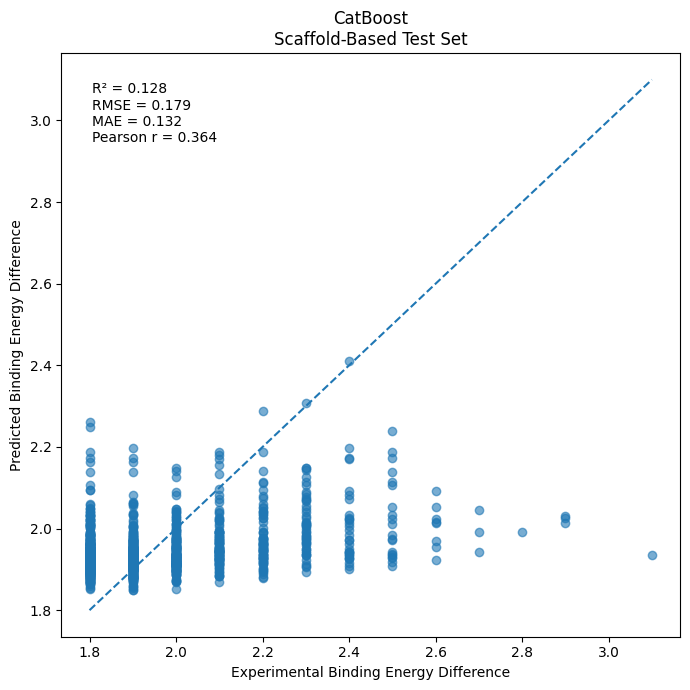

In [49]:
# ============================================================
# STEP 34: PREDICTED VS EXPERIMENTAL
# ============================================================

import matplotlib.pyplot as plt

best_predictions = test_predictions[
    best_model_name
]

plt.figure(
    figsize=(7, 7)
)

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.6
)

min_value = min(
    y_test.min(),
    best_predictions.min()
)

max_value = max(
    y_test.max(),
    best_predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel(
    "Experimental Binding Energy Difference"
)

plt.ylabel(
    "Predicted Binding Energy Difference"
)

plt.title(
    f"{best_model_name}\n"
    "Scaffold-Based Test Set"
)

metrics = calculate_metrics(
    y_test,
    best_predictions
)

text = (
    f"R² = {metrics['R2']:.3f}\n"
    f"RMSE = {metrics['RMSE']:.3f}\n"
    f"MAE = {metrics['MAE']:.3f}\n"
    f"Pearson r = {metrics['Pearson_r']:.3f}"
)

plt.text(
    0.05,
    0.95,
    text,
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.tight_layout()

plt.savefig(
    "scaffold_predicted_vs_experimental.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

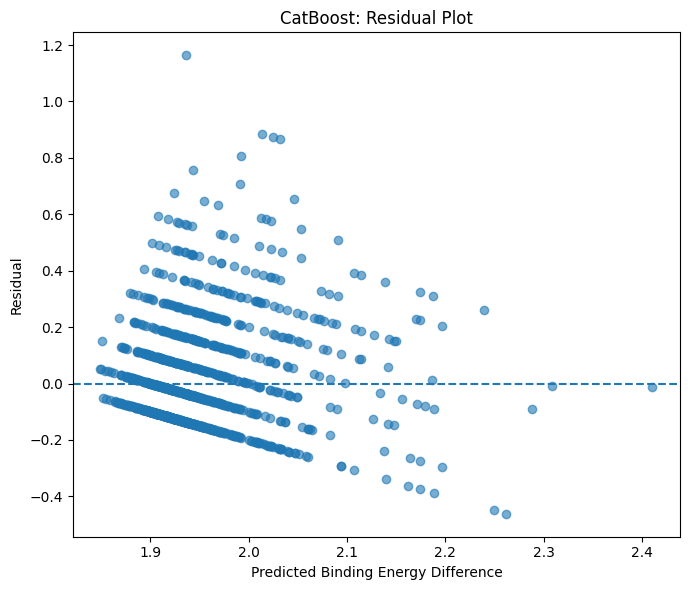

In [50]:
# ============================================================
# STEP 35: RESIDUAL PLOT
# ============================================================

residuals = (
    y_test.values
    -
    best_predictions
)

plt.figure(
    figsize=(7, 6)
)

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.6
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Predicted Binding Energy Difference"
)

plt.ylabel(
    "Residual"
)

plt.title(
    f"{best_model_name}: Residual Plot"
)

plt.tight_layout()

plt.savefig(
    "scaffold_residual_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:
# ============================================================
# STEP 36: FEATURE IMPORTANCE
# ============================================================

if best_model_name in [
    "XGBoost",
    "Random Forest",
    "CatBoost",
    "LightGBM"
]:

    fitted_model = best_model.named_steps[
        "model"
    ]

    importance = (
        fitted_model.feature_importances_
    )

    feature_names = X_train.columns
    importance_170 = importance[0:170]
    feature_names_170 = feature_names[0:170]
       
    feature_importance_df = pd.DataFrame({"Feature": feature_names_170, "Importance": importance_170})

    feature_importance_df = (
        feature_importance_df
        .sort_values(
            "Importance",
            ascending=False
        )
        .reset_index(drop=True)
    )

    print(
        feature_importance_df.head(50)
    )

    feature_importance_df.to_csv(
        "feature_importance.csv",
        index=False
    )

                Feature  Importance
0                   qed    3.072569
1             PEOE_VSA7    2.807772
2               BertzCT    2.165628
3           VSA_EState3    2.049995
4           fr_bicyclic    1.861354
5                  TPSA    1.784220
6           EState_VSA5    1.691133
7           EState_VSA3    1.598850
8           VSA_EState8    1.585952
9                   Ipc    1.562868
10            PEOE_VSA8    1.552690
11         BCUT2D_MRLOW    1.508850
12          VSA_EState2    1.494122
13             SMR_VSA6    1.453305
14        BCUT2D_LOGPHI    1.426715
15              MolLogP    1.414834
16             SMR_VSA3    1.401399
17    NumRotatableBonds    1.346912
18            PEOE_VSA6    1.325730
19       MinEStateIndex    1.308328
20             SMR_VSA5    1.300141
21          VSA_EState4    1.261072
22          EState_VSA8    1.226787
23          VSA_EState7    1.210033
24  MinAbsPartialCharge    1.205003
25           SlogP_VSA5    1.203350
26            PEOE_VSA9    1

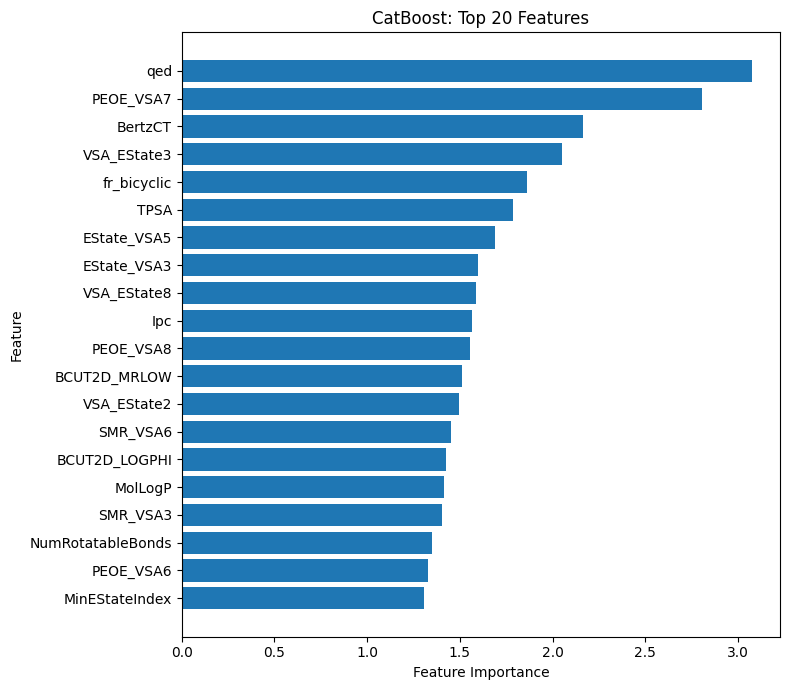

In [52]:
# ============================================================
# STEP 37: TOP 20 FEATURE IMPORTANCE
# ============================================================

if best_model_name in [
    "XGBoost",
    "Random Forest",
    "CatBoost",
    "LightGBM"
]:

    top_features = (
        feature_importance_df
        .head(20)
        .sort_values(
            "Importance"
        )
    )

    plt.figure(
        figsize=(8, 7)
    )

    plt.barh(
        top_features["Feature"],
        top_features["Importance"]
    )

    plt.xlabel(
        "Feature Importance"
    )

    plt.ylabel(
        "Feature"
    )

    plt.title(
        f"{best_model_name}: "
        "Top 20 Features"
    )

    plt.tight_layout()

    plt.savefig(
        "top_20_features.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [53]:
# ============================================================
# STEP 38: SCAFFOLD DISTRIBUTION
# ============================================================

train_scaffold_counts = (
    groups_train
    .value_counts()
    .rename("Train_Count")
)

test_scaffold_counts = (
    groups_test
    .value_counts()
    .rename("Test_Count")
)

scaffold_distribution = pd.concat(
    [
        train_scaffold_counts,
        test_scaffold_counts
    ],
    axis=1
)

scaffold_distribution.to_csv(
    "scaffold_distribution.csv"
)

print(
    scaffold_distribution.head(20)
)

                                                    Train_Count  Test_Count
Scaffold                                                                   
c1ccccc1                                                  261.0         NaN
C1CCC2C(C1)CCC1C3CCCC3CCC21                                73.0         NaN
O=C1C2ON(c3ccccc3)C(c3ccccc3)C2C(=O)N1c1ccccc1             51.0         NaN
O=C(COC(=O)c1cccc(N2C(=O)c3ccccc3C2=O)c1)Nc1ccccc1         42.0         NaN
O=C(COC(=O)c1cccc(N2C(=O)C3CC=CCC3C2=O)c1)Nc1cc...         42.0         NaN
O=C1CCC2C1CCC1C3CCCCC3CCC21                                38.0         NaN
O=c1/c(=C\c2ccccc2)sc2n1C(c1ccccc1)C1=C(N=2)c2c...         36.0         NaN
c1ccc(-c2ccco2)cc1                                         34.0         NaN
c1ccc(-n2ccnn2)cc1                                         33.0         NaN
O=C(COC(=O)c1ccc2c(c1)C(=O)N(c1ccccc1)C2=O)c1cc...         33.0         NaN
O=C(NCc1ccccc1)c1cccc(-c2nc3cccnc3[nH]2)c1                 24.0         NaN
O=C1C=C2CCC3